# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Registration No: 037 | Name: Kiran**

In [1]:
!pip install -q medmnist opencv-python scikit-image scikit-learn matplotlib pandas

## Personal Settings (first cell)

In [11]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, cv2, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from medmnist import BloodMNIST

REG = "037"
SEED = int(REG[-2:])                       # last two digits -> 37
HOG_CELL = 8 if int(REG[-1]) % 2 == 0 else 16   # last digit 7 is odd -> 16
GRID = 4 if int(REG[-1]) <= 4 else 6       # last digit 7 -> 6x6 grid (36 keypoints)
np.random.seed(SEED)
print("Seed:", SEED, "| HOG cell:", HOG_CELL, "x", HOG_CELL, "| SIFT grid:", GRID, "x", GRID, "=", GRID*GRID, "keypoints")

Seed: 37 | HOG cell: 16 x 16 | SIFT grid: 6 x 6 = 36 keypoints


# Q1. Data setup

train shape: (400, 128, 128) | class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val shape: (120, 128, 128) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test shape: (120, 128, 128) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


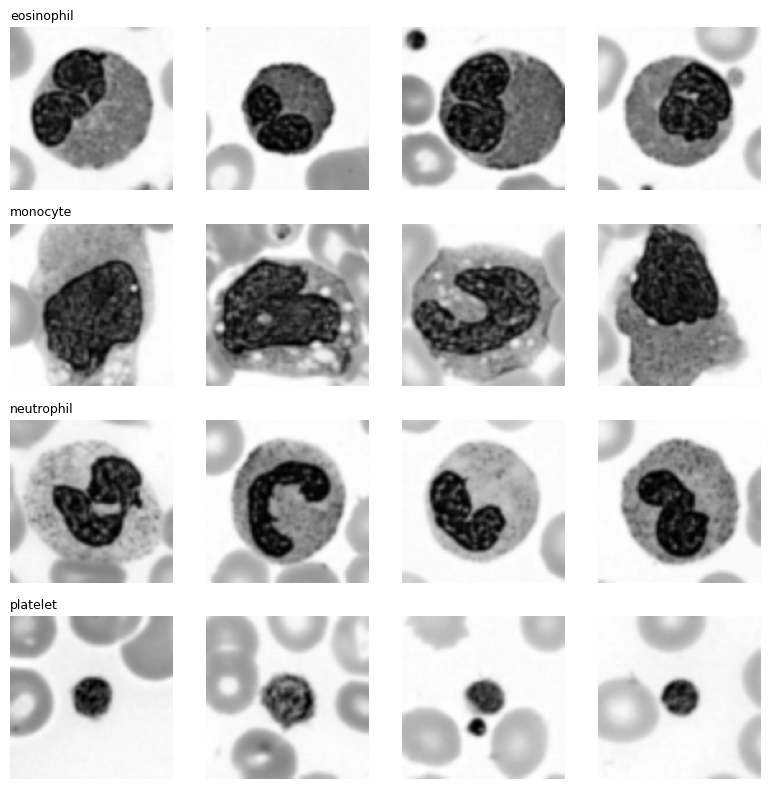

In [12]:
CLASS_IDS = [1, 5, 6, 7]
NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N = {"train": 100, "val": 30, "test": 30}
rng = np.random.RandomState(SEED)

def load(split, n):
    ds = BloodMNIST(split=split, download=True, size=64)
    imgs, labs = ds.imgs, ds.labels.ravel()
    X, y = [], []
    for new, c in enumerate(CLASS_IDS):
        idx = np.where(labs == c)[0]
        for i in rng.choice(idx, n, replace=False):
            g = cv2.cvtColor(imgs[i], cv2.COLOR_RGB2GRAY)          # grayscale
            g = cv2.resize(g, (128, 128), interpolation=cv2.INTER_LINEAR)  # 128x128
            X.append(g); y.append(new)
    return np.array(X, dtype=np.uint8), np.array(y)

Xtr, ytr = load("train", N["train"])
Xva, yva = load("val", N["val"])
Xte, yte = load("test", N["test"])
for name, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    print(name, "shape:", X.shape, "| class counts:", {NAMES[k]: v for k, v in sorted(Counter(y).items())})

fig, ax = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idx = np.where(ytr == r)[0][:4]
    for c in range(4):
        ax[r, c].imshow(Xtr[idx[c]], cmap="gray"); ax[r, c].axis("off")
        if c == 0: ax[r, c].set_title(NAMES[r], fontsize=9, loc="left")
plt.tight_layout(); plt.show()

# Q2. HOG + SVM

**HOG feature length (by hand), cell = 16x16, image = 128x128, 9 orientations, 2x2 cells per block, block stride = 1 cell:**
- Cells per side = 128 / 16 = 8, so 8 x 8 cells
- Blocks per side = 8 - 2 + 1 = 7, so 7 x 7 = 49 blocks
- Values per block = 2 x 2 cells x 9 orientations = 36
- **Total = 49 x 36 = 1764**

HOG feature length: 1764 | matches hand calculation (1764): True


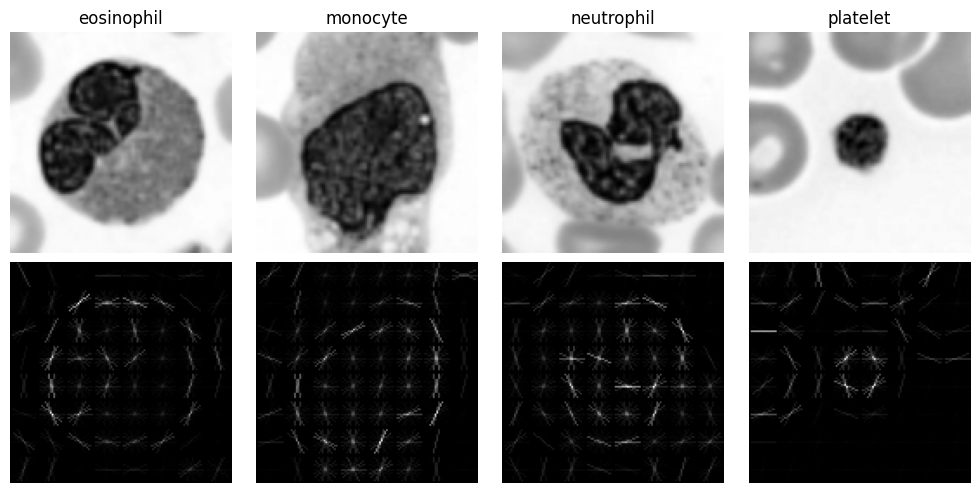

In [13]:
def hog_feat(img, vis=False):
    return hog(img / 255.0, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm="L2-Hys", visualize=vis, feature_vector=True)

def hog_all(X): return np.array([hog_feat(i) for i in X])

Htr, Hva = hog_all(Xtr), hog_all(Xva)
print("HOG feature length:", Htr.shape[1], "| matches hand calculation (1764):", Htr.shape[1] == 1764)

fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for r in range(4):
    img = Xtr[np.where(ytr == r)[0][0]]
    _, h = hog_feat(img, vis=True)
    ax[0, r].imshow(img, cmap="gray"); ax[0, r].set_title(NAMES[r]); ax[0, r].axis("off")
    ax[1, r].imshow(exposure.rescale_intensity(h, in_range=(0, h.max() + 1e-9)), cmap="gray"); ax[1, r].axis("off")
plt.tight_layout(); plt.show()

In [14]:
def fit_svm(Xa, ya, Xb, yb):
    best = None
    for C in [0.1, 1, 10]:
        m = make_pipeline(StandardScaler(), LinearSVC(C=C, max_iter=20000, random_state=SEED))
        m.fit(Xa, ya)
        acc = accuracy_score(yb, m.predict(Xb))
        print(f"C={C}: validation accuracy = {acc:.4f}")
        if best is None or acc > best[0]: best = (acc, C, m)
    print("Best C:", best[1])
    return best[2], best[1]

def report(model, X, y, title):
    p = model.predict(X)
    print(f"{title}: accuracy = {accuracy_score(y, p):.4f} | macro-F1 = {f1_score(y, p, average='macro'):.4f}")
    cm = confusion_matrix(y, p)
    print(pd.DataFrame(cm, index=["true_" + n for n in NAMES], columns=["pred_" + n for n in NAMES]))
    return cm

hog_model, hog_C = fit_svm(Htr, ytr, Hva, yva)
cm_hog = report(hog_model, Hva, yva, "HOG + SVM (validation)")

C=0.1: validation accuracy = 0.7250
C=1: validation accuracy = 0.7333
C=10: validation accuracy = 0.7333
Best C: 1
HOG + SVM (validation): accuracy = 0.7333 | macro-F1 = 0.7340
                 pred_eosinophil  pred_monocyte  pred_neutrophil  \
true_eosinophil               17              9                4   
true_monocyte                  7             20                3   
true_neutrophil                6              3               21   
true_platelet                  0              0                0   

                 pred_platelet  
true_eosinophil              0  
true_monocyte                0  
true_neutrophil              0  
true_platelet               30  


# Q3. SIFT + SVM

Keypoints per image -> average: 72.48, min: 4, max: 213
Images with zero keypoints: 0


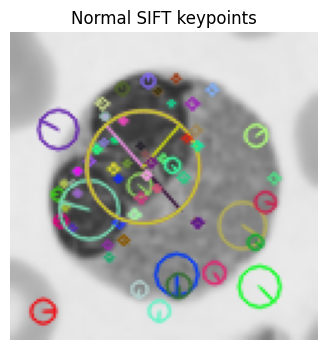

In [15]:
sift = cv2.SIFT_create()
counts, kp_first = [], None
for i, img in enumerate(Xtr):
    kp, _ = sift.detectAndCompute(img, None)
    counts.append(len(kp))
    if kp_first is None and len(kp) > 0: kp_first, img_first = kp, img
counts = np.array(counts)
print(f"Keypoints per image -> average: {counts.mean():.2f}, min: {counts.min()}, max: {counts.max()}")
print("Images with zero keypoints:", int((counts == 0).sum()))
vis = cv2.drawKeypoints(img_first, kp_first, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4, 4)); plt.imshow(vis, cmap="gray"); plt.axis("off"); plt.title("Normal SIFT keypoints"); plt.show()

**Why is a different keypoint count a problem for an SVM?** Each keypoint gives a 128-value descriptor, so images with different numbers of keypoints produce feature vectors of different lengths (and an image with zero keypoints gives nothing), but an SVM needs every image to have the same fixed-length feature vector.

**Fixed-grid SIFT feature length (by hand):** grid = 6 x 6 = 36 keypoints, each descriptor has 128 values, so length = 36 x 128 = **4608**.

In [7]:
step = 128 / GRID
GRID_PTS = [(step * (j + 0.5), step * (i + 0.5)) for i in range(GRID) for j in range(GRID)]

def sift_feat(img):
    kps = [cv2.KeyPoint(float(x), float(y), 32) for x, y in GRID_PTS]   # keypoint size 32
    _, d = sift.compute(img, kps)
    return d.flatten()

def sift_all(X): return np.array([sift_feat(i) for i in X])

Str, Sva = sift_all(Xtr), sift_all(Xva)
print("Grid SIFT feature length:", Str.shape[1], "| matches hand calculation (36 x 128 = 4608):", Str.shape[1] == GRID * GRID * 128)

sift_model, sift_C = fit_svm(Str, ytr, Sva, yva)
cm_sift = report(sift_model, Sva, yva, "SIFT + SVM (validation)")

Grid SIFT feature length: 4608 | matches hand calculation (36 x 128 = 4608): True
C=0.1: validation accuracy = 0.7167
C=1: validation accuracy = 0.7250
C=10: validation accuracy = 0.7250
Best C: 1
SIFT + SVM (validation): accuracy = 0.7250 | macro-F1 = 0.7211
                 pred_eosinophil  pred_monocyte  pred_neutrophil  \
true_eosinophil               15              7                7   
true_monocyte                  9             18                3   
true_neutrophil                4              1               25   
true_platelet                  0              0                1   

                 pred_platelet  
true_eosinophil              1  
true_monocyte                0  
true_neutrophil              0  
true_platelet               29  


# Q4. Robustness

**Prediction (written before running the test):**
- **Rotation:** I think **HOG** will lose more accuracy, because HOG stores gradient-orientation histograms in fixed cells, so a 20 degree turn shifts the orientation bins and moves content between cells.
- **Noise:** I think **HOG** will lose more accuracy, because HOG works directly on raw pixel gradients, which noise changes a lot, while SIFT's Gaussian smoothing and large 32-pixel patches average the noise out.

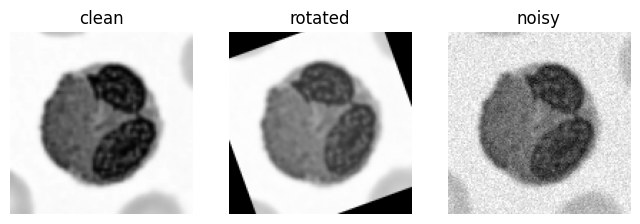

            Clean accuracy  Rotated accuracy  Noisy accuracy
HOG + SVM           0.7167            0.5333          0.2500
SIFT + SVM          0.7583            0.5167          0.7333


In [16]:
PRED_ROT, PRED_NOISE = "HOG", "HOG"   # must match the prediction written above

def rotate(X, angle=20):
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)
    return np.array([cv2.warpAffine(i, M, (128, 128)) for i in X])

noise_rng = np.random.RandomState(SEED)
def add_noise(X, sigma=0.05):
    out = X / 255.0 + noise_rng.normal(0, sigma, X.shape)     # image scaled to 0-1
    return (np.clip(out, 0, 1) * 255).round().astype(np.uint8)

tests = {"clean": Xte, "rotated": rotate(Xte), "noisy": add_noise(Xte)}   # change applied BEFORE feature extraction

fig, ax = plt.subplots(1, 3, figsize=(8, 3))
for a, (k, v) in zip(ax, tests.items()):
    a.imshow(v[0], cmap="gray"); a.set_title(k); a.axis("off")
plt.show()

res = {"HOG + SVM": {}, "SIFT + SVM": {}}
for k, imgs in tests.items():
    res["HOG + SVM"][k] = accuracy_score(yte, hog_model.predict(hog_all(imgs)))
    res["SIFT + SVM"][k] = accuracy_score(yte, sift_model.predict(sift_all(imgs)))
table = pd.DataFrame(res).T
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
print(table.round(4))

In [17]:
d = {m: (r["clean"] - r["rotated"], r["clean"] - r["noisy"]) for m, r in res.items()}
worst_rot = max(d, key=lambda m: d[m][0]).split()[0]
worst_noise = max(d, key=lambda m: d[m][1]).split()[0]
ok_rot, ok_noise = worst_rot == PRED_ROT, worst_noise == PRED_NOISE
print(f"Accuracy drop under rotation -> HOG: {d['HOG + SVM'][0]:.4f}, SIFT: {d['SIFT + SVM'][0]:.4f}")
print(f"Accuracy drop under noise    -> HOG: {d['HOG + SVM'][1]:.4f}, SIFT: {d['SIFT + SVM'][1]:.4f}")
print()
print(f"Sentence 1: Under rotation, {worst_rot} lost more accuracy (HOG {d['HOG + SVM'][0]:.3f} vs SIFT {d['SIFT + SVM'][0]:.3f}), so my rotation prediction ({PRED_ROT}) was {'correct' if ok_rot else 'wrong'}.")
print(f"Sentence 2: Under noise, {worst_noise} lost more accuracy (HOG {d['HOG + SVM'][1]:.3f} vs SIFT {d['SIFT + SVM'][1]:.3f}), so my noise prediction ({PRED_NOISE}) was {'correct' if ok_noise else 'wrong'}.")
print(f"Sentence 3: Clean accuracy was HOG {res['HOG + SVM']['clean']:.3f} and SIFT {res['SIFT + SVM']['clean']:.3f}, so the table shows which pipeline is more reliable overall when images change.")

Accuracy drop under rotation -> HOG: 0.1833, SIFT: 0.2417
Accuracy drop under noise    -> HOG: 0.4667, SIFT: 0.0250

Sentence 1: Under rotation, SIFT lost more accuracy (HOG 0.183 vs SIFT 0.242), so my rotation prediction (HOG) was wrong.
Sentence 2: Under noise, HOG lost more accuracy (HOG 0.467 vs SIFT 0.025), so my noise prediction (HOG) was correct.
Sentence 3: Clean accuracy was HOG 0.717 and SIFT 0.758, so the table shows which pipeline is more reliable overall when images change.


**Was my prediction correct? (3 sentences, copied from the output above):** *(paste the three printed sentences here)*

# Q5. Short answers and AI log

**(a) Why does HOG use block normalisation?** Gradient strength changes with lighting and contrast, so the same cell can give very different histogram values in different images. Normalising each block of cells makes the features less sensitive to these brightness and contrast changes, which makes the descriptor more reliable.

**(b) Why is it wrong to choose C using the test set?** The test set must only measure how the final model performs on unseen data. If C is picked using test accuracy, the test set influences the model, so the reported accuracy becomes too optimistic. C must be chosen on the validation set, and the test set used once at the end.

In [18]:
def top_pair(cm):
    c = cm.copy(); np.fill_diagonal(c, 0)
    i, j = np.unravel_index(c.argmax(), c.shape)
    return NAMES[i], NAMES[j], c[i, j]
for n, cm in [("HOG", cm_hog), ("SIFT", cm_sift)]:
    a, b, k = top_pair(cm)
    print(f"{n}: most confused pair (validation) = true {a} predicted as {b}, {k} times")

HOG: most confused pair (validation) = true eosinophil predicted as monocyte, 9 times
SIFT: most confused pair (validation) = true monocyte predicted as eosinophil, 9 times


**Most confused classes and why grayscale makes it harder:** *(fill in from the printed pair above; typically eosinophil vs neutrophil)*. These cells have similar size, round shape and lobed nuclei, and one of the main differences between them is the colour of the granules (eosinophils have red/orange granules). Converting to grayscale removes colour, so only shape and texture remain, which makes the classes look more alike.

**AI log**

| Prompt (one line) | What I changed | How I checked it was correct |
|---|---|---|
| Asked an AI tool to write the full HOG vs SIFT notebook for this exam | Set my seed (37), HOG cell (16x16) and SIFT grid (6x6) from registration 037; wrote my own prediction in Q4 | Printed shapes and class counts, checked HOG length = 1764 and SIFT length = 4608 against my hand calculation, looked at the HOG, keypoint and rotated/noisy pictures |